# 02 — PIB e PIB per capita dos municípios de SC (D32)

Perguntas: como o PIB nominal evoluiu, quais municípios o concentram, como mudou a participação dos
maiores e como os municípios se comparam em PIB per capita.

Os dados vêm só das views do schema `gold`, lidas como `bed_readonly` pelas funções de `brasil_em_dados.analise`. Os valores aparecem como estão na GOLD (R\$, habitantes, %): nenhuma conversão de unidade (regra 11); os eixos só abreviam o texto dos rótulos.

Regras que valem para a leitura:
- **PIB é nominal** (regra 3): a preços correntes; variação entre anos inclui inflação e não é
  crescimento econômico real.
- **PIB per capita é o publicado pelo IBGE, sem recálculo, e não é renda** (regra 4).
- **Sem per capita agregado**: por região, só somas de PIB e de população.

In [1]:
%matplotlib inline

from brasil_em_dados.analise import calculos, consultas
from brasil_em_dados.analise import graficos as g
from brasil_em_dados.db import engine_readonly

engine = engine_readonly()  # bed_readonly; cada consulta roda numa transação READ ONLY
g.configurar_tabelas()  # números das tabelas no padrão brasileiro

## 1. PIB nominal de SC, 2010–2023

PIB nominal: R$ 153,7 bi (2010) → R$ 513,4 bi (2023); 3,34 vezes, em valores correntes


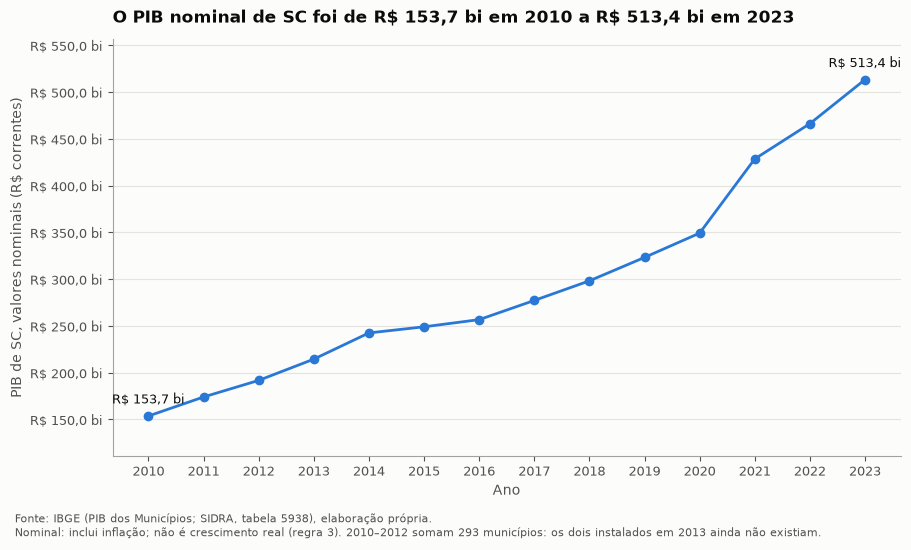

In [2]:
pib_sc = consultas.agregado(engine, "estado", "pib_corrente")
inicio, fim = pib_sc["valor"].iloc[0], pib_sc["valor"].iloc[-1]
razao = f"{fim / inicio:.2f}".replace(".", ",")
print(f"PIB nominal: {g.formatar_reais(inicio)} (2010) → {g.formatar_reais(fim)} (2023); "
      f"{razao} vezes, em valores correntes")
g.serie_anual(
    pib_sc["ano"].tolist(), pib_sc["valor"].tolist(),
    titulo=f"O PIB nominal de SC foi de {g.formatar_reais(inicio)} em 2010 a {g.formatar_reais(fim)} em 2023",
    rotulo_eixo="PIB de SC, valores nominais (R$ correntes)",
    fonte=g.FONTE_PIB, formatar=g.formatar_reais,
    nota="Nominal: inclui inflação; não é crescimento real (regra 3). 2010–2012 somam 293 municípios: "
         "os dois instalados em 2013 ainda não existiam.")

In [3]:
calculos.variacao_sequencial(pib_sc)[["ano", "valor", "variacao_percentual"]].rename(columns={
    "valor": "PIB nominal (R$)", "variacao_percentual": "Variação nominal sobre o ano anterior (%)"})

,ano,PIB nominal (R$),Variação nominal sobre o ano anterior (%)
0,2010,"153.726.009.000,00",NaN
1,2011,"174.068.321.000,00","13,23"
2,2012,"191.794.656.000,00","10,18"
3,2013,"214.512.250.000,00","11,84"
4,2014,"242.553.374.000,00","13,07"
5,2015,"249.079.644.000,00","2,69"
6,2016,"256.754.675.000,00","3,08"
7,2017,"277.270.232.000,00","7,99"
8,2018,"298.227.085.000,00","7,56"
9,2019,"323.263.861.000,00","8,40"


**Leitura.** Em valores correntes, o PIB de SC ficou 3,3 vezes maior entre 2010 e 2023. Esse número
mistura aumento de preços e de volume e não deve ser lido como crescimento real (regra 3). O salto
nominal de 2021 (+22,7%) foi investigado no alerta A2: os anos de 2021 a 2023 foram revisados pelo
IBGE em 19/12/2025, e 2022–2023 ainda estão sujeitos a revisão (limitações, seção 5).

## 2. Concentração do PIB (2023)

Os 10 maiores somam 46,1% do PIB de SC; metade do PIB está em 13 municípios.


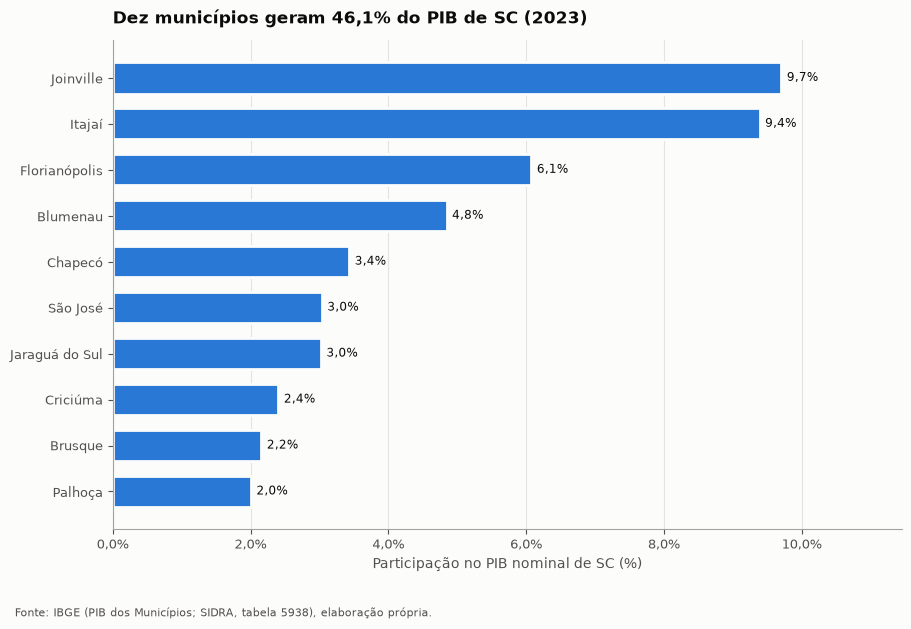

In [4]:
part_pib_2023 = consultas.participacao(engine, "pib_corrente", 2023)
top_pib = calculos.top_n(part_pib_2023, "valor")
acumulada = calculos.participacao_acumulada(part_pib_2023)
metade = calculos.quantos_somam(part_pib_2023)
print(f"Os 10 maiores somam {g.formatar_percentual(acumulada)} do PIB de SC; "
      f"metade do PIB está em {metade} municípios.")
g.barras_horizontais(
    top_pib["nome_municipio"], top_pib["participacao_percentual"],
    titulo=f"Dez municípios geram {g.formatar_percentual(acumulada)} do PIB de SC (2023)",
    rotulo_eixo="Participação no PIB nominal de SC (%)",
    fonte=g.FONTE_PIB, formatar=g.formatar_percentual)

**Leitura.** O PIB é mais concentrado que a população: os dez maiores geram 46,1% do PIB (contra
40,6% da população), e metade do PIB está em 13 municípios (contra 17 na população). Itajaí é o 2º em
PIB e o 5º em população.

## 3. Participação dos maiores municípios: 2010 × 2023

A participação de um município no PIB do estado é a razão entre dois valores do **mesmo ano**, ambos
a preços correntes daquele ano. O nível geral de preços aparece no numerador e no denominador e se
cancela: por isso a participação pode ser comparada entre 2010 e 2023 sem deflacionar. O que a
participação não elimina são as diferenças de preços entre atividades: se os preços de um setor sobem
mais que a média, os municípios especializados nele ganham participação mesmo sem produzir mais.

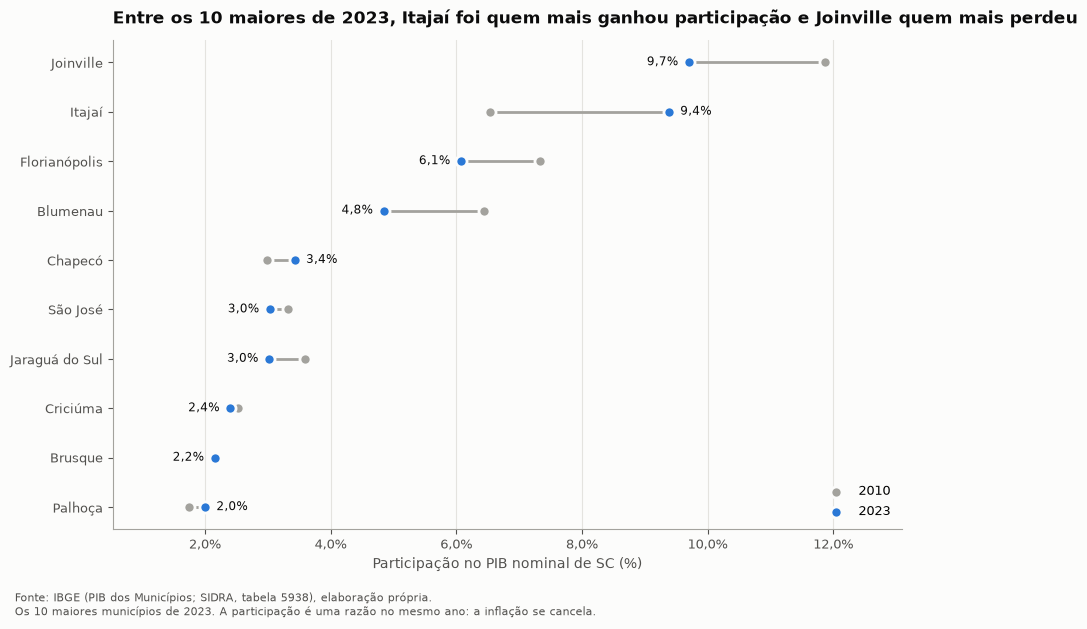

In [5]:
part_pib_2010 = consultas.participacao(engine, "pib_corrente", 2010)
comparacao = calculos.anexar(top_pib, part_pib_2010, ["participacao_percentual"], sufixo="_2010")
diferenca = comparacao["participacao_percentual"] - comparacao["participacao_percentual_2010"]
ganhou = comparacao["nome_municipio"][diferenca.idxmax()]
perdeu = comparacao["nome_municipio"][diferenca.idxmin()]
g.comparacao_dois_anos(
    comparacao["nome_municipio"], comparacao["participacao_percentual_2010"],
    comparacao["participacao_percentual"], ano_inicio=2010, ano_fim=2023,
    titulo=f"Entre os 10 maiores de 2023, {ganhou} foi quem mais ganhou participação e {perdeu} quem mais perdeu",
    rotulo_eixo="Participação no PIB nominal de SC (%)",
    fonte=g.FONTE_PIB, formatar=g.formatar_percentual,
    nota="Os 10 maiores municípios de 2023. A participação é uma razão no mesmo ano: a inflação se cancela.")

In [6]:
comparacao.assign(diferenca_pp=diferenca)[
    ["nome_municipio", "participacao_percentual_2010", "participacao_percentual", "diferenca_pp"]]

,nome_municipio,participacao_percentual_2010,participacao_percentual,diferenca_pp
0,Joinville,"11,87","9,70","-2,17"
1,Itajaí,"6,54","9,39","2,84"
2,Florianópolis,"7,34","6,08","-1,26"
3,Blumenau,"6,45","4,84","-1,60"
4,Chapecó,"3,00","3,43","0,44"
5,São José,"3,33","3,03","-0,29"
6,Jaraguá do Sul,"3,59","3,02","-0,57"
7,Criciúma,"2,52","2,40","-0,11"
8,Brusque,"2,18","2,16","-0,02"
9,Palhoça,"1,75","2,01","0,26"


**Leitura.** Itajaí passou de 6,5% para 9,4% do PIB estadual, 0,3 ponto abaixo de Joinville, que caiu
de 11,9% para 9,7%. Florianópolis também perdeu participação (7,3% → 6,1%). Os dez maiores de 2023
somavam 48,6% do PIB em 2010 e 46,1% em 2023, uma queda de 2,5 pontos. Lembrete: o PIB municipal é uma
distribuição do PIB estadual feita pelo IBGE com indicadores por atividade (limitações, seção 6).

## 4. PIB per capita em 2023

Mediana: R$ 52.591; de R$ 16.142 a R$ 218.626 (13,5 vezes)


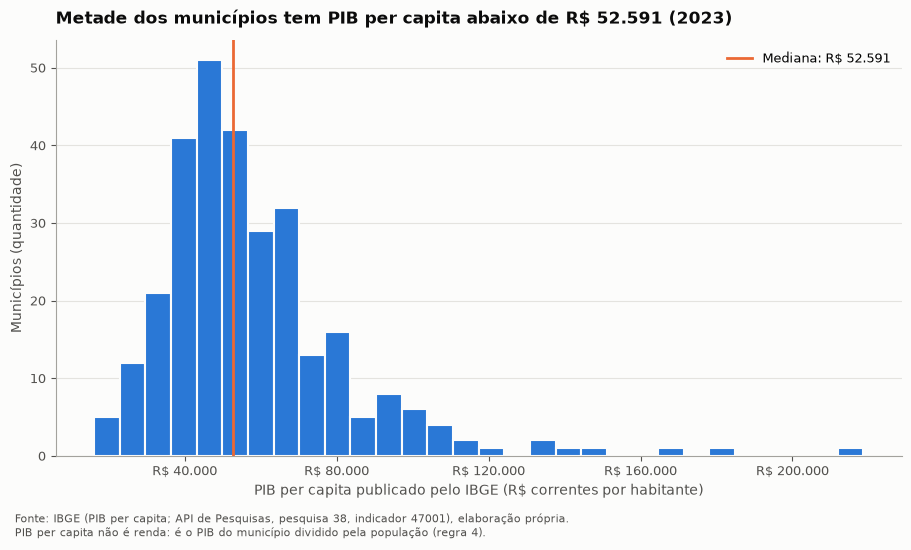

In [7]:
painel_2023 = consultas.painel(engine, 2023)
painel_2022 = consultas.painel(engine, 2022)
per_capita = calculos.anexar(painel_2023, painel_2022, ["pop_censo"], sufixo="_2022")
resumo = calculos.resumo(per_capita["pib_per_capita_reais"])
razao = f"{resumo.maximo / resumo.minimo:.1f}".replace(".", ",")
print(f"Mediana: {g.formatar_reais(resumo.mediana)}; de {g.formatar_reais(resumo.minimo)} a "
      f"{g.formatar_reais(resumo.maximo)} ({razao} vezes)")
g.histograma(
    per_capita["pib_per_capita_reais"],
    titulo=f"Metade dos municípios tem PIB per capita abaixo de {g.formatar_reais(resumo.mediana)} (2023)",
    rotulo_eixo="PIB per capita publicado pelo IBGE (R$ correntes por habitante)",
    fonte=g.FONTE_PER_CAPITA, formatar=g.formatar_reais,
    nota="PIB per capita não é renda: é o PIB do município dividido pela população (regra 4).")

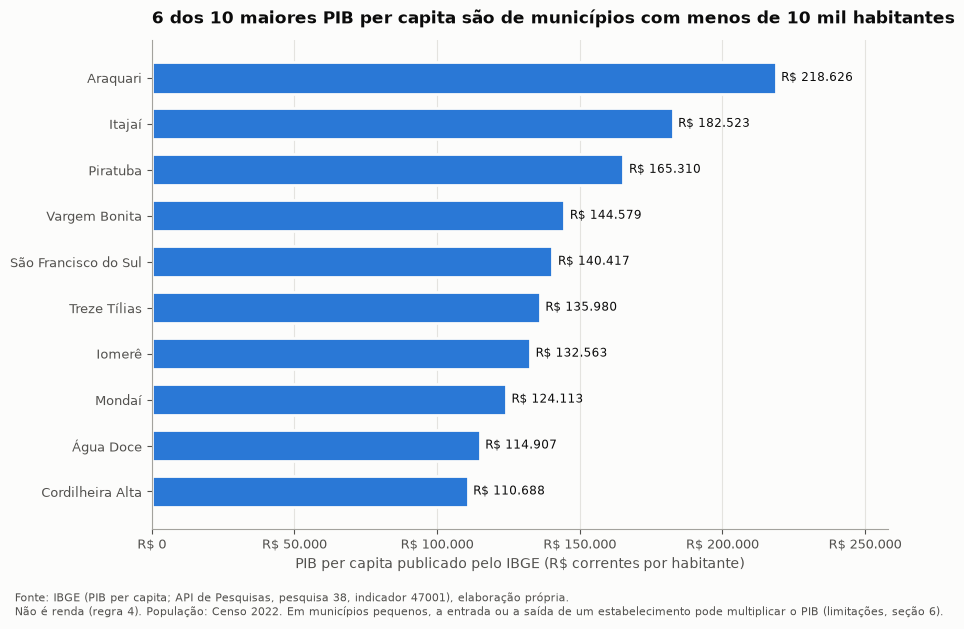

In [8]:
maiores = calculos.top_n(per_capita, "pib_per_capita_reais")
pequenos = int((maiores["pop_censo_2022"] < 10_000).sum())
g.barras_horizontais(
    maiores["nome_municipio"], maiores["pib_per_capita_reais"],
    titulo=f"{pequenos} dos 10 maiores PIB per capita são de municípios com menos de 10 mil habitantes",
    rotulo_eixo="PIB per capita publicado pelo IBGE (R$ correntes por habitante)",
    fonte=g.FONTE_PER_CAPITA, formatar=g.formatar_reais,
    nota="Não é renda (regra 4). População: Censo 2022. Em municípios pequenos, a entrada ou a saída de um "
         "estabelecimento pode multiplicar o PIB (limitações, seção 6).")

In [9]:
maiores[["nome_municipio", "pib_per_capita_reais", "pop_censo_2022"]].rename(columns={
    "nome_municipio": "Município", "pib_per_capita_reais": "PIB per capita 2023 (R$)",
    "pop_censo_2022": "População (Censo 2022)"})

,Município,PIB per capita 2023 (R$),População (Censo 2022)
0,Araquari,"218.625,97","45.283,00"
1,Itajaí,"182.522,93","264.054,00"
2,Piratuba,"165.309,60","5.769,00"
3,Vargem Bonita,"144.578,53","4.576,00"
4,São Francisco do Sul,"140.417,13","52.674,00"
5,Treze Tílias,"135.979,77","8.787,00"
6,Iomerê,"132.563,15","2.877,00"
7,Mondaí,"124.112,53","10.066,00"
8,Água Doce,"114.906,54","6.508,00"
9,Cordilheira Alta,"110.687,66","4.781,00"


Dos 10 menores, 4 têm 'Balneário' no nome.


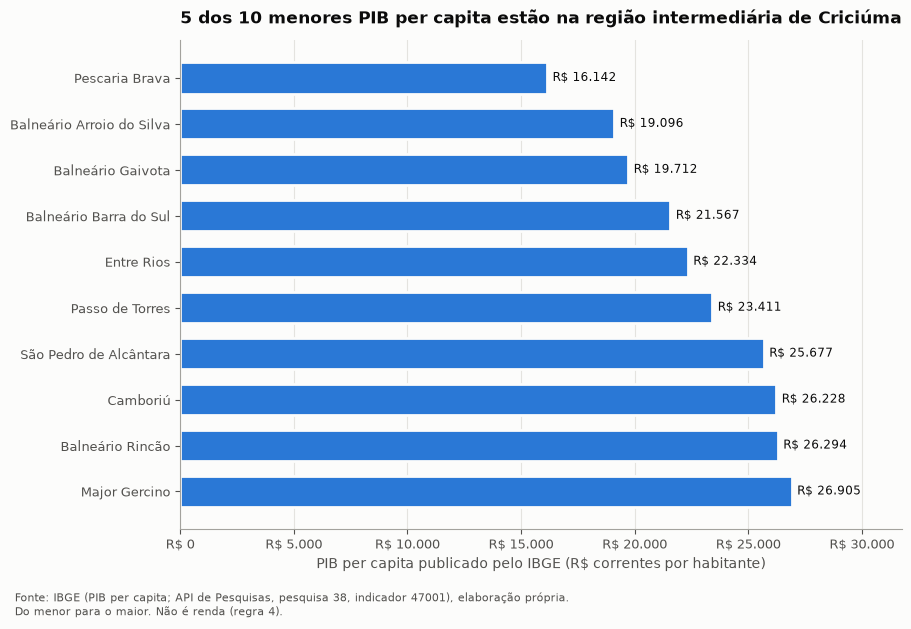

In [10]:
menores = calculos.top_n(per_capita, "pib_per_capita_reais", maiores=False)
regiao_menores = menores["nome_regiao_intermediaria"].value_counts()
com_balneario = int(menores["nome_municipio"].str.contains("Balneário").sum())
print(f"Dos 10 menores, {com_balneario} têm 'Balneário' no nome.")
g.barras_horizontais(
    menores["nome_municipio"], menores["pib_per_capita_reais"],
    titulo=f"{regiao_menores.iloc[0]} dos 10 menores PIB per capita estão na região intermediária de "
           f"{regiao_menores.index[0]}",
    rotulo_eixo="PIB per capita publicado pelo IBGE (R$ correntes por habitante)",
    fonte=g.FONTE_PER_CAPITA, formatar=g.formatar_reais,
    nota="Do menor para o maior. Não é renda (regra 4).")

In [11]:
saltos = calculos.saltos_anuais(consultas.variacao_anual(engine, "pib_corrente"))
pop_dos_saltos = calculos.anexar(saltos.drop_duplicates("cod_municipio"), painel_2022,
                                 ["pop_censo"], sufixo="_2022")
print(f"Variações anuais do PIB nominal acima de 50% em módulo: {len(saltos)}, "
      f"em {saltos['cod_municipio'].nunique()} municípios.")
print(f"População mediana desses municípios (Censo 2022): "
      f"{g.formatar_habitantes(pop_dos_saltos['pop_censo_2022'].median())}")
calculos.top_n(saltos, "variacao_percentual", 5)[["nome_municipio", "ano", "variacao_percentual"]]

Variações anuais do PIB nominal acima de 50% em módulo: 61, em 51 municípios.
População mediana desses municípios (Censo 2022): 3,6 mil


,nome_municipio,ano,variacao_percentual
0,Lajeado Grande,2012,"215,24"
1,Entre Rios,2011,"210,87"
2,Paial,2011,"203,28"
3,Vargem,2014,"134,16"
4,Rio Fortuna,2013,"131,94"


**Leitura.** O PIB per capita mediano foi de R\$ 52,6 mil em 2023. O maior (Araquari, R\$ 218,6 mil)
é 13,5 vezes o menor (Pescaria Brava, R\$ 16,1 mil). Dos dez maiores, seis têm menos de 10 mil
habitantes (Censo 2022), e o topo também inclui Itajaí, com 264 mil. Na outra ponta, cinco dos dez
menores estão na região intermediária de Criciúma, e quatro dos dez têm "Balneário" no nome.

Saltos anuais (alerta A1): a GOLD tem 61 variações anuais do PIB nominal acima de 50% em módulo, em
51 municípios, com população mediana de 3,6 mil habitantes (Censo 2022). Segundo as limitações
(seção 6), em municípios pequenos a entrada ou a saída de um estabelecimento pode multiplicar o PIB de
um ano para outro; a causa de cada caso é **NÃO CONFIRMADA**. O per capita não é renda dos moradores,
e o denominador muda conforme o ano (seção 9).

## 5. Regiões intermediárias: somas de PIB e de população (2022)

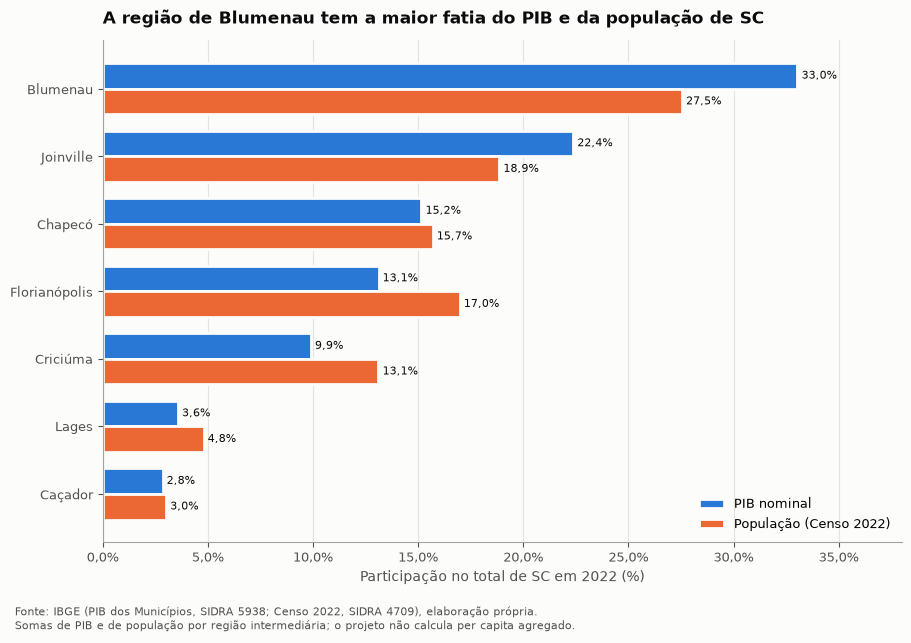

In [12]:
pib_reg = consultas.agregado(engine, "regiao_intermediaria", "pib_corrente")
pop_reg = consultas.agregado(engine, "regiao_intermediaria", "pop_censo")
part_pib_reg = calculos.participacao_no_total(pib_reg[pib_reg["ano"] == 2022])
part_pop_reg = calculos.participacao_no_total(pop_reg[pop_reg["ano"] == 2022])
regioes = calculos.anexar(part_pib_reg, part_pop_reg, ["participacao_percentual"],
                          chave="nome_regiao", sufixo="_pop")
g.barras_pareadas(
    regioes["nome_regiao"], regioes["participacao_percentual"],
    regioes["participacao_percentual_pop"], nome_a="PIB nominal", nome_b="População (Censo 2022)",
    titulo=f"A região de {regioes['nome_regiao'][0]} tem a maior fatia do PIB e da população de SC",
    rotulo_eixo="Participação no total de SC em 2022 (%)",
    fonte=g.FONTE_PIB_E_CENSO, formatar=g.formatar_percentual,
    nota="Somas de PIB e de população por região intermediária; o projeto não calcula per capita agregado.")

**Leitura.** As regiões de Blumenau e Joinville têm participação no PIB maior que na população; nas
de Florianópolis e Criciúma acontece o contrário. A comparação é só entre as duas participações:
o projeto não divide o PIB regional pela população para criar um per capita regional, porque o per
capita oficial é municipal e tem denominadores próprios (regra 4; limitações, seção 9).